# Air Quality Prediction Using Supervised Machine Learning
### CA-4 | Supervised Machine Learning | Google Colab

**Project focus:** Predict hourly carbon monoxide concentration, `CO(GT)`, using gas-sensor responses and meteorological measurements.

**Important scope note:** The UCI Air Quality dataset does not contain an official AQI column. Therefore, this project predicts `CO(GT)` in mg/m³ as an air-quality indicator. It does **not** calculate or predict an official AQI category or national AQI score.

**Dataset:** UCI Machine Learning Repository — Air Quality (9,358 hourly observations, collected in an Italian city from March 2004 to April 2005).

**Workflow:** data loading → cleaning → EDA → feature engineering → chronological 70:30 split → baseline regression → hyperparameter tuning → evaluation → interpretation.

## 1. Import Libraries

In [4]:
import os, zipfile, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

OUTPUT_DIR = Path("/content/aqi_project_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Download and Load the UCI Dataset
The notebook downloads the official UCI ZIP archive and reads the Excel file. If the download URL changes, use the official UCI dataset page linked in the report.

In [5]:
import ssl
import urllib.request
import zipfile
import shutil
from pathlib import Path
import pandas as pd

DATA_URL = "https://cdn.uci-ics-mlr-prod.aws.uci.edu/360/air%2Bquality.zip"
ZIP_PATH = "/content/AirQualityUCI.zip"
DATA_DIR = Path("/content/air_quality_data")
DATA_DIR.mkdir(exist_ok=True)

# Create an unverified SSL context to bypass certificate expiration issues
ssl_context = ssl._create_unverified_context()

# Use the unverified context to download the file
with urllib.request.urlopen(DATA_URL, context=ssl_context) as response, open(ZIP_PATH, 'wb') as out_file:
    shutil.copyfileobj(response, out_file)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATA_DIR)

xlsx_files = list(DATA_DIR.rglob("AirQualityUCI.xlsx"))
if not xlsx_files:
    raise FileNotFoundError("AirQualityUCI.xlsx was not found inside the downloaded UCI archive.")

raw_df = pd.read_excel(xlsx_files[0], engine="openpyxl")
raw_df = raw_df.dropna(how="all").copy()
print("Raw dataset shape:", raw_df.shape)
display(raw_df.head())

Raw dataset shape: (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10,18:00:00,2.6,1360.00,150,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754
1,2004-03-10,19:00:00,2.0,1292.25,112,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487
2,2004-03-10,20:00:00,2.2,1402.00,88,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239
3,2004-03-10,21:00:00,2.2,1375.50,80,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713
4,2004-03-10,22:00:00,1.6,1272.25,51,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794


## 3. Dataset Overview and Feature Meaning

In [6]:
print("Shape:", raw_df.shape)
print("\nColumns:")
print(raw_df.columns.tolist())
print("\nData types:")
display(raw_df.dtypes.to_frame("Data Type"))
print("\nStatistical summary:")
display(raw_df.describe(include="all").T)

Shape: (9357, 15)

Columns:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']

Data types:


,Data Type
Date,datetime64[ns]
Time,object
CO(GT),float64
PT08.S1(CO),float64
NMHC(GT),int64
C6H6(GT),float64
PT08.S2(NMHC),float64
NOx(GT),float64
PT08.S3(NOx),float64
NO2(GT),float64



Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Date,9357,NaN,NaN,NaN,2004-09-21 04:30:05.193972480,2004-03-10 00:00:00,2004-06-16 00:00:00,2004-09-21 00:00:00,2004-12-28 00:00:00,2005-04-04 00:00:00,NaN
Time,9357,24,18:00:00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),9357.0,NaN,NaN,NaN,-34.207524,-200.0,0.6,1.5,2.6,11.9,77.65717
PT08.S1(CO),9357.0,NaN,NaN,NaN,1048.869652,-200.0,921.0,1052.5,1221.25,2039.75,329.817015
NMHC(GT),9357.0,NaN,NaN,NaN,-159.090093,-200.0,-200.0,-200.0,-200.0,1189.0,139.789093
C6H6(GT),9357.0,NaN,NaN,NaN,1.865576,-200.0,4.004958,7.886653,13.636091,63.741476,41.380154
PT08.S2(NMHC),9357.0,NaN,NaN,NaN,894.475963,-200.0,711.0,894.5,1104.75,2214.0,342.315902
NOx(GT),9357.0,NaN,NaN,NaN,168.6042,-200.0,50.0,141.0,284.2,1479.0,257.424561
PT08.S3(NOx),9357.0,NaN,NaN,NaN,794.872333,-200.0,637.0,794.25,960.25,2682.75,321.977031
NO2(GT),9357.0,NaN,NaN,NaN,58.135898,-200.0,53.0,96.0,133.0,339.7,126.931428


## 4. Data Cleaning
The original dataset uses `-200` to represent missing sensor/reference readings. These values are converted to NaN. Date and time are combined into a timestamp. Rows without a valid target value are excluded because a supervised model cannot learn from a missing target.

In [7]:
df = raw_df.copy()
df.columns = [str(c).strip() for c in df.columns]

# Convert sentinel missing values to NaN across numeric columns.
for col in df.columns:
    if col not in ["Date", "Time"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df.loc[df[col] == -200, col] = np.nan

# Parse date and time.
date_part = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
time_part = pd.to_timedelta(df["Time"].astype(str), errors="coerce")
df["DateTime"] = date_part + time_part
df = df.dropna(subset=["DateTime"]).sort_values("DateTime").reset_index(drop=True)

target = "CO(GT)"
if target not in df.columns:
    raise KeyError(f"Expected target column {target} not found.")

before_target_drop = len(df)
df = df.dropna(subset=[target]).copy()
print("Rows removed because target was missing:", before_target_drop - len(df))
print("Cleaned shape after removing missing target:", df.shape)
display(df.head())

Rows removed because target was missing: 1683
Cleaned shape after removing missing target: (7674, 16)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,DateTime
0,2004-03-10,18:00:00,2.6,1360.00,150.0,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754,2004-03-10 18:00:00
1,2004-03-10,19:00:00,2.0,1292.25,112.0,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487,2004-03-10 19:00:00
2,2004-03-10,20:00:00,2.2,1402.00,88.0,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239,2004-03-10 20:00:00
3,2004-03-10,21:00:00,2.2,1375.50,80.0,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713,2004-03-10 21:00:00
4,2004-03-10,22:00:00,1.6,1272.25,51.0,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794,2004-03-10 22:00:00


## 5. Missing Value Analysis

,Missing Count,Missing Percentage
NMHC(GT),6784,88.40
NO2(GT),416,5.42
NOx(GT),413,5.38
PT08.S1(CO),330,4.30
PT08.S2(NMHC),330,4.30
PT08.S4(NO2),330,4.30
PT08.S3(NOx),330,4.30
C6H6(GT),330,4.30
T,330,4.30
RH,330,4.30


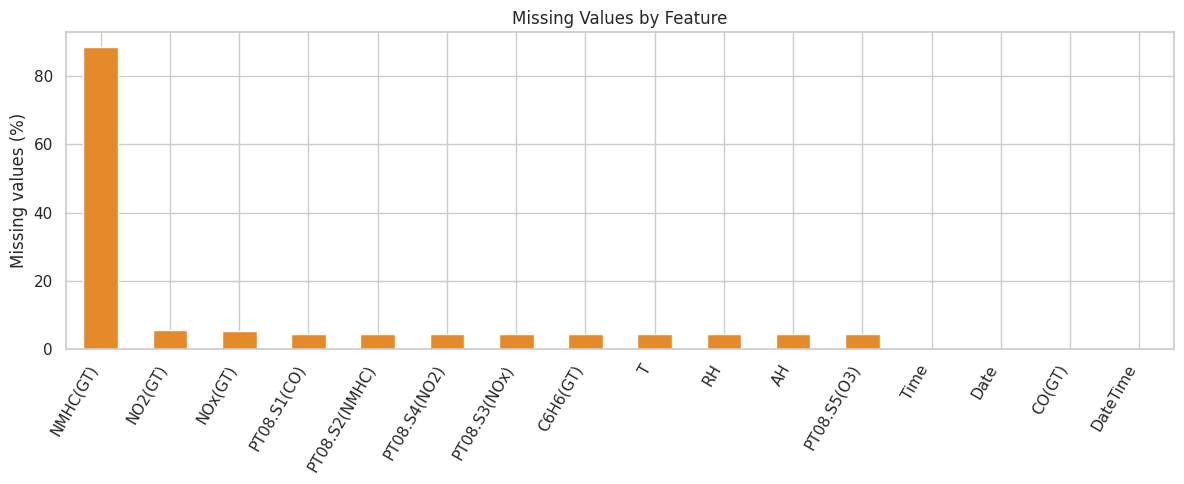

In [8]:
missing_count = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_table = pd.DataFrame({"Missing Count": missing_count, "Missing Percentage": missing_pct.round(2)})
display(missing_table)
plt.figure(figsize=(12,5))
missing_table["Missing Percentage"].plot(kind="bar", color="#E58A2B")
plt.title("Missing Values by Feature")
plt.ylabel("Missing values (%)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR/"missing_values.png", dpi=180)
plt.show()

## 6. Duplicate Analysis

In [9]:
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate removal:", df.shape)

Exact duplicate rows: 0
Shape after duplicate removal: (7674, 16)


## 7. Target Variable Analysis — CO(GT)

count    7674.000000
mean        2.152750
std         1.453252
min         0.100000
25%         1.100000
50%         1.800000
75%         2.900000
max        11.900000
Name: CO(GT), dtype: float64


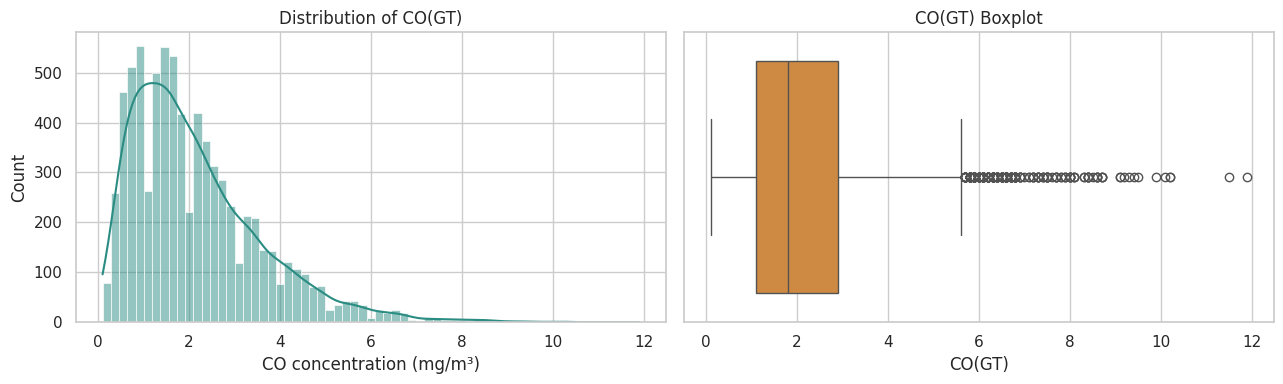

In [10]:
print(df[target].describe())
fig, axes = plt.subplots(1, 2, figsize=(13,4))
sns.histplot(df[target], kde=True, ax=axes[0], color="#2A8C82")
axes[0].set_title("Distribution of CO(GT)")
axes[0].set_xlabel("CO concentration (mg/m³)")
sns.boxplot(x=df[target], ax=axes[1], color="#E58A2B")
axes[1].set_title("CO(GT) Boxplot")
plt.tight_layout()
plt.savefig(FIG_DIR/"target_distribution.png", dpi=180)
plt.show()

## 8. Time-Based Analysis

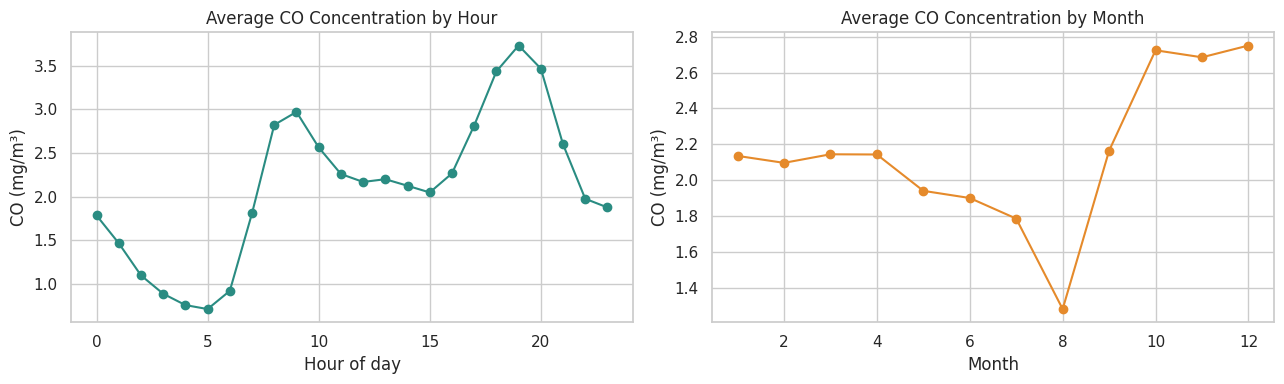

In [11]:
df["Hour"] = df["DateTime"].dt.hour
df["Month"] = df["DateTime"].dt.month
df["DayOfWeek"] = df["DateTime"].dt.dayofweek
df["DayOfYear"] = df["DateTime"].dt.dayofyear

hourly_mean = df.groupby("Hour")[target].mean()
monthly_mean = df.groupby("Month")[target].mean()

fig, axes = plt.subplots(1,2,figsize=(13,4))
hourly_mean.plot(marker="o", ax=axes[0], color="#2A8C82")
axes[0].set_title("Average CO Concentration by Hour")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("CO (mg/m³)")
monthly_mean.plot(marker="o", ax=axes[1], color="#E58A2B")
axes[1].set_title("Average CO Concentration by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("CO (mg/m³)")
plt.tight_layout()
plt.savefig(FIG_DIR/"time_analysis.png", dpi=180)
plt.show()

## 9. Sensor and Weather Feature Distributions

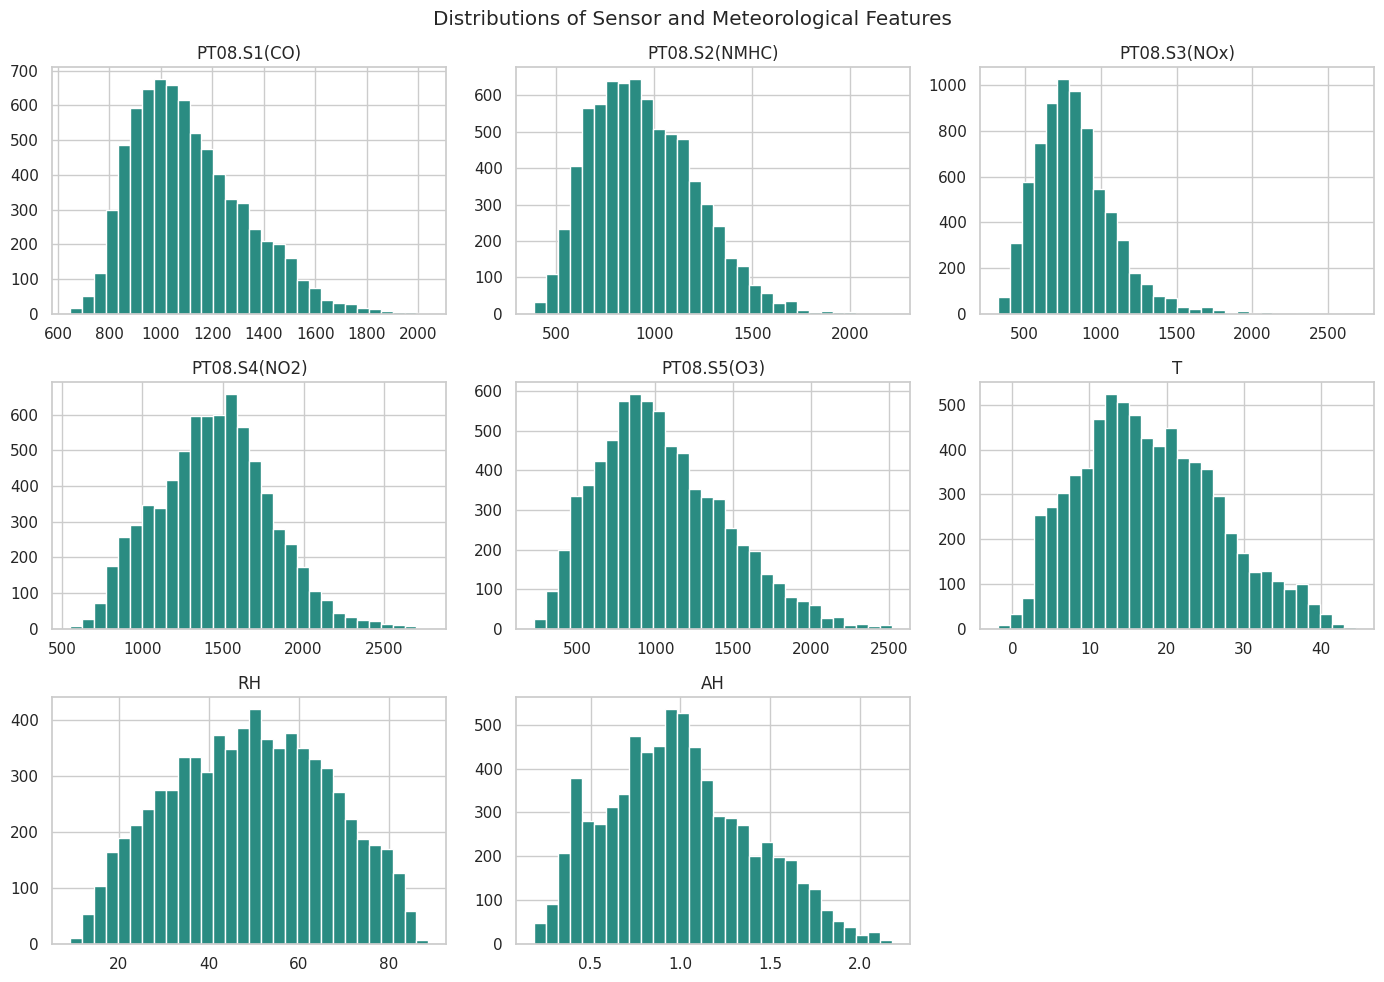

In [12]:
candidate_plot_cols = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"]
available_plot_cols = [c for c in candidate_plot_cols if c in df.columns]
df[available_plot_cols].hist(figsize=(14,10), bins=30, color="#2A8C82", edgecolor="white")
plt.suptitle("Distributions of Sensor and Meteorological Features")
plt.tight_layout()
plt.savefig(FIG_DIR/"feature_distributions.png", dpi=180)
plt.show()

## 10. Correlation Analysis

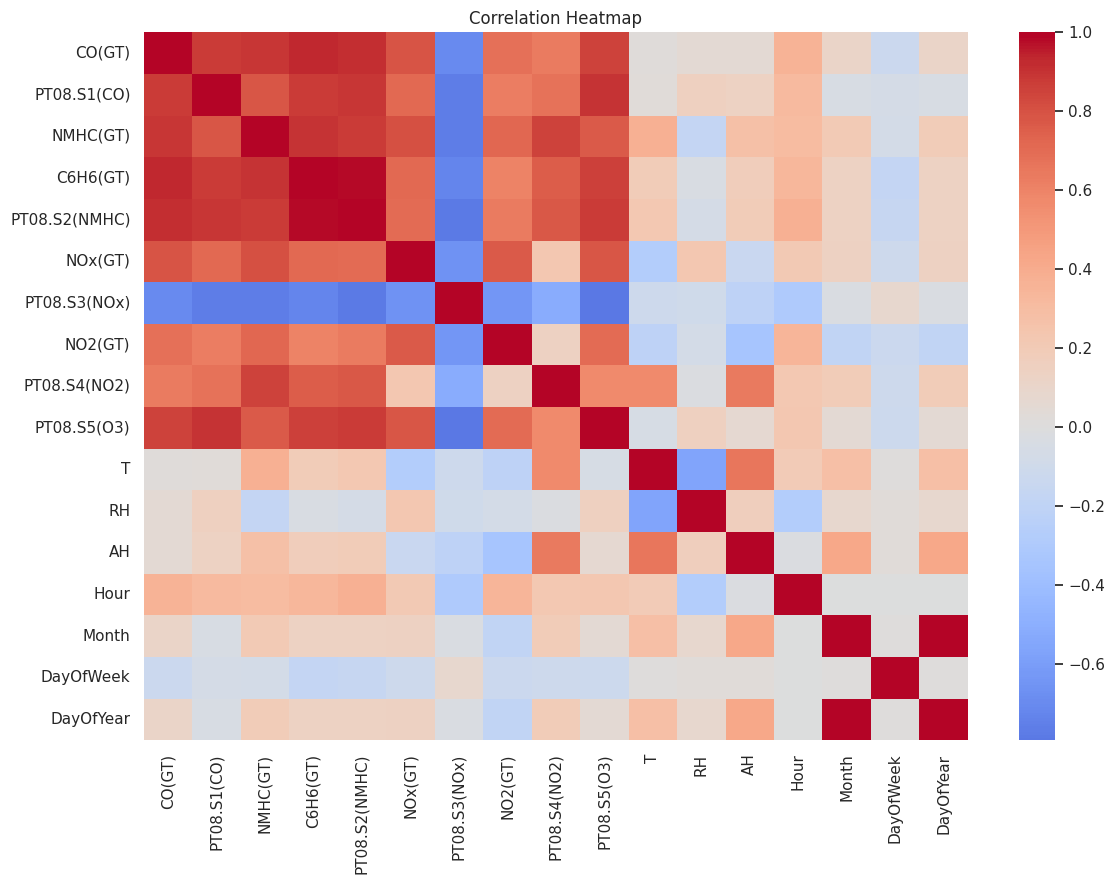

,Correlation with CO(GT)
C6H6(GT),0.931091
PT08.S2(NMHC),0.915519
NMHC(GT),0.889734
PT08.S1(CO),0.879292
PT08.S5(O3),0.854183
NOx(GT),0.795054
PT08.S3(NOx),-0.703433
NO2(GT),0.683533
PT08.S4(NO2),0.630700
Hour,0.358159


In [13]:
numeric_for_corr = df.select_dtypes(include=np.number)
corr = numeric_for_corr.corr()
plt.figure(figsize=(12,9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(FIG_DIR/"correlation_heatmap.png", dpi=180)
plt.show()

target_corr = corr[target].drop(target).sort_values(key=lambda x: x.abs(), ascending=False)
display(target_corr.to_frame("Correlation with CO(GT)"))

## 11. Outlier Detection Using IQR
IQR flags are used for inspection, not automatic deletion. High pollutant readings may represent real pollution events.

In [14]:
outlier_rows = []
for col in [target] + available_plot_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    count = ((s < lower) | (s > upper)).sum()
    outlier_rows.append([col, lower, upper, int(count), 100*count/len(s)])
outlier_table = pd.DataFrame(outlier_rows, columns=["Feature","Lower Bound","Upper Bound","IQR Flags","Flagged Percentage"])
display(outlier_table.round(3))
outlier_table.to_csv(OUTPUT_DIR/"outlier_summary.csv", index=False)

,Feature,Lower Bound,Upper Bound,IQR Flags,Flagged Percentage
0,CO(GT),-1.600,5.600,215,2.802
1,PT08.S1(CO),496.844,1695.094,90,1.225
2,PT08.S2(NMHC),169.531,1698.781,46,0.626
3,PT08.S3(NOx),183.781,1425.031,193,2.628
4,PT08.S4(NO2),497.406,2378.156,66,0.899
5,PT08.S5(O3),-95.656,2144.594,65,0.885
6,T,-7.762,42.737,6,0.082
7,RH,-5.187,103.113,0,0.000
8,AH,-0.143,2.099,18,0.245


## 12. Feature Engineering and Predictor Selection
To estimate CO concentration from sensor and weather data, the other certified reference pollutant columns (`NMHC(GT)`, `C6H6(GT)`, `NOx(GT)`, `NO2(GT)`) are excluded from predictors. This avoids using other ground-truth analyzer measurements as shortcuts. Sensor responses and meteorological variables are retained.

In [15]:
# Cyclic hour representation.
df["Hour_Sin"] = np.sin(2*np.pi*df["Hour"]/24)
df["Hour_Cos"] = np.cos(2*np.pi*df["Hour"]/24)

sensor_cols = [c for c in ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)"] if c in df.columns]
weather_cols = [c for c in ["T", "RH", "AH"] if c in df.columns]
time_cols = ["Hour_Sin", "Hour_Cos", "DayOfWeek", "Month", "DayOfYear"]
feature_cols = sensor_cols + weather_cols + time_cols

X = df[feature_cols].copy()
y = df[target].copy()
print("Predictor features:", feature_cols)
print("Number of predictors:", len(feature_cols))
print("Target:", target, "(mg/m³)")

Predictor features: ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Hour_Sin', 'Hour_Cos', 'DayOfWeek', 'Month', 'DayOfYear']
Number of predictors: 13
Target: CO(GT) (mg/m³)


## 13. Chronological 70:30 Train-Test Split
The observations are sorted by timestamp before splitting. This simulates using earlier observations to predict later observations and avoids random mixing of past and future data.

In [16]:
split_index = int(len(df)*0.70)
X_train, X_test = X.iloc[:split_index].copy(), X.iloc[split_index:].copy()
y_train, y_test = y.iloc[:split_index].copy(), y.iloc[split_index:].copy()

print("Training rows:", len(X_train), f"({len(X_train)/len(df)*100:.2f}%)")
print("Testing rows:", len(X_test), f"({len(X_test)/len(df)*100:.2f}%)")
print("Training period:", df["DateTime"].iloc[0], "to", df["DateTime"].iloc[split_index-1])
print("Testing period:", df["DateTime"].iloc[split_index], "to", df["DateTime"].iloc[-1])

Training rows: 5371 (69.99%)
Testing rows: 2303 (30.01%)
Training period: 2004-03-10 18:00:00 to 2004-12-21 11:00:00
Testing period: 2004-12-21 12:00:00 to 2005-04-04 14:00:00


## 14. Preprocessing Pipeline
Median imputation handles remaining missing predictor values. Standard scaling is used for Linear Regression and KNN. Tree-based models use imputation without scaling.

In [17]:
def make_preprocessor(scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return Pipeline(steps)

def make_model_pipeline(model, scale=False):
    return Pipeline([
        ("preprocessor", make_preprocessor(scale=scale)),
        ("model", model)
    ])

models = {
    "Linear Regression": make_model_pipeline(LinearRegression(), scale=True),
    "Decision Tree": make_model_pipeline(DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE)),
    "KNN": make_model_pipeline(KNeighborsRegressor(n_neighbors=5), scale=True),
    "Random Forest": make_model_pipeline(RandomForestRegressor(n_estimators=120, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_model_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE))
}
print("Preprocessing pipelines created.")

Preprocessing pipelines created.


## 15. Evaluation Metrics

In [18]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred)
    }

## 16. Train Baseline Regression Models

In [19]:
baseline_rows = []
fitted_models = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    metrics = regression_metrics(y_test, pred)
    baseline_rows.append({"Model": name, **metrics})
    fitted_models[name] = pipe

baseline_results = pd.DataFrame(baseline_rows).sort_values("RMSE")
display(baseline_results.round(4))
baseline_results.to_csv(OUTPUT_DIR/"baseline_model_results.csv", index=False)

,Model,MAE,RMSE,R2
4,Gradient Boosting,0.4367,0.6946,0.7653
2,KNN,0.4733,0.7041,0.7588
3,Random Forest,0.4505,0.7071,0.7567
1,Decision Tree,0.5850,0.8787,0.6244
0,Linear Regression,1.5102,1.6576,-0.3366


## 17. Baseline Model Comparison

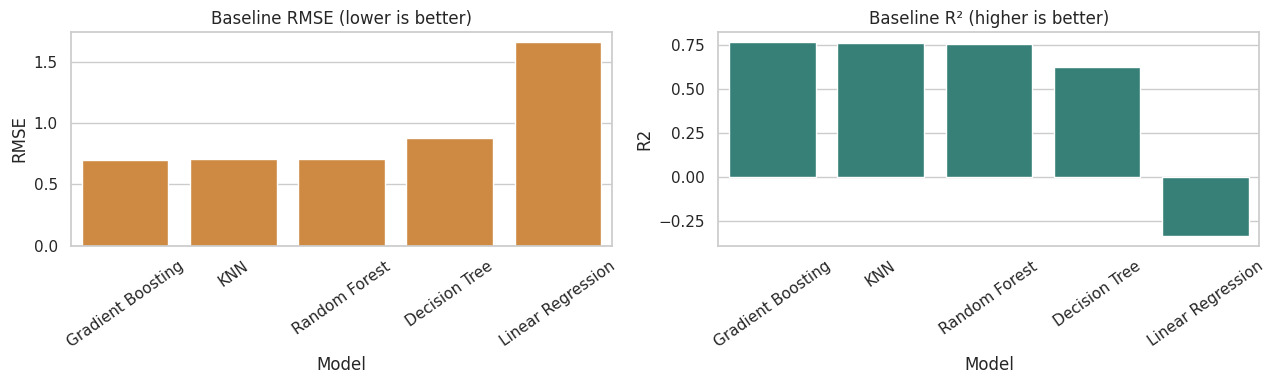

In [20]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
sns.barplot(data=baseline_results, x="Model", y="RMSE", ax=axes[0], color="#E58A2B")
axes[0].set_title("Baseline RMSE (lower is better)")
axes[0].tick_params(axis="x", rotation=35)
sns.barplot(data=baseline_results, x="Model", y="R2", ax=axes[1], color="#2A8C82")
axes[1].set_title("Baseline R² (higher is better)")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.savefig(FIG_DIR/"baseline_model_comparison.png", dpi=180)
plt.show()

## 18. Hyperparameter Tuning with GridSearchCV
The two ensemble models are tuned using five-fold TimeSeriesSplit cross-validation. The test set is kept separate from the search.

In [21]:
tscv = TimeSeriesSplit(n_splits=5)

rf_pipe = make_model_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
rf_grid = {
    "model__n_estimators": [100, 150],
    "model__max_depth": [10, None],
    "model__min_samples_split": [2, 5]
}
rf_search = GridSearchCV(rf_pipe, rf_grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
rf_search.fit(X_train, y_train)
print("Best Random Forest parameters:", rf_search.best_params_)
print("Best RF CV RMSE:", -rf_search.best_score_)

gb_pipe = make_model_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE))
gb_grid = {
    "model__n_estimators": [100, 150],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}
gb_search = GridSearchCV(gb_pipe, gb_grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gb_search.fit(X_train, y_train)
print("Best Gradient Boosting parameters:", gb_search.best_params_)
print("Best GB CV RMSE:", -gb_search.best_score_)

Best Random Forest parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 150}
Best RF CV RMSE: 0.49843795349555275
Best Gradient Boosting parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}
Best GB CV RMSE: 0.49625704936570597


## 19. Final Model Comparison

In [22]:
final_candidates = dict(fitted_models)
final_candidates["Random Forest (Tuned)"] = rf_search.best_estimator_
final_candidates["Gradient Boosting (Tuned)"] = gb_search.best_estimator_

final_rows = []
final_predictions = {}
for name, model in final_candidates.items():
    pred = model.predict(X_test)
    final_predictions[name] = pred
    final_rows.append({"Model": name, **regression_metrics(y_test, pred)})

final_results = pd.DataFrame(final_rows).sort_values("RMSE").reset_index(drop=True)
display(final_results.round(4))
final_results.to_csv(OUTPUT_DIR/"final_model_results.csv", index=False)

best_model_name = final_results.iloc[0]["Model"]
best_model = final_candidates[best_model_name]
best_predictions = final_predictions[best_model_name]
print("Selected model (lowest test RMSE):", best_model_name)

,Model,MAE,RMSE,R2
0,Gradient Boosting,0.4367,0.6946,0.7653
1,KNN,0.4733,0.7041,0.7588
2,Random Forest (Tuned),0.4491,0.7043,0.7587
3,Random Forest,0.4505,0.7071,0.7567
4,Gradient Boosting (Tuned),0.4827,0.7215,0.7468
5,Decision Tree,0.5850,0.8787,0.6244
6,Linear Regression,1.5102,1.6576,-0.3366


Selected model (lowest test RMSE): Gradient Boosting


## 20. Actual vs Predicted Values

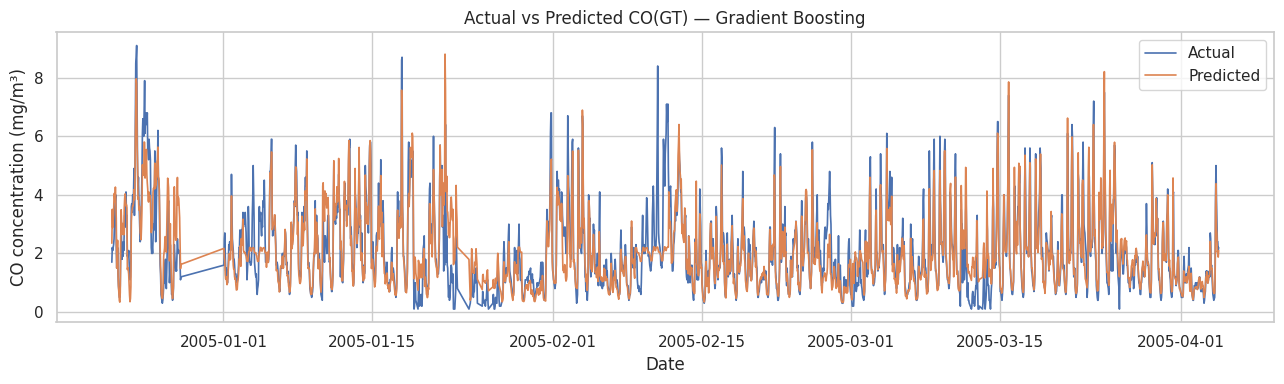

In [23]:
plt.figure(figsize=(13,4))
plt.plot(df["DateTime"].iloc[split_index:], y_test.values, label="Actual", linewidth=1.2)
plt.plot(df["DateTime"].iloc[split_index:], best_predictions, label="Predicted", linewidth=1.2)
plt.title(f"Actual vs Predicted CO(GT) — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("CO concentration (mg/m³)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR/"actual_vs_predicted.png", dpi=180)
plt.show()

## 21. Residual Analysis

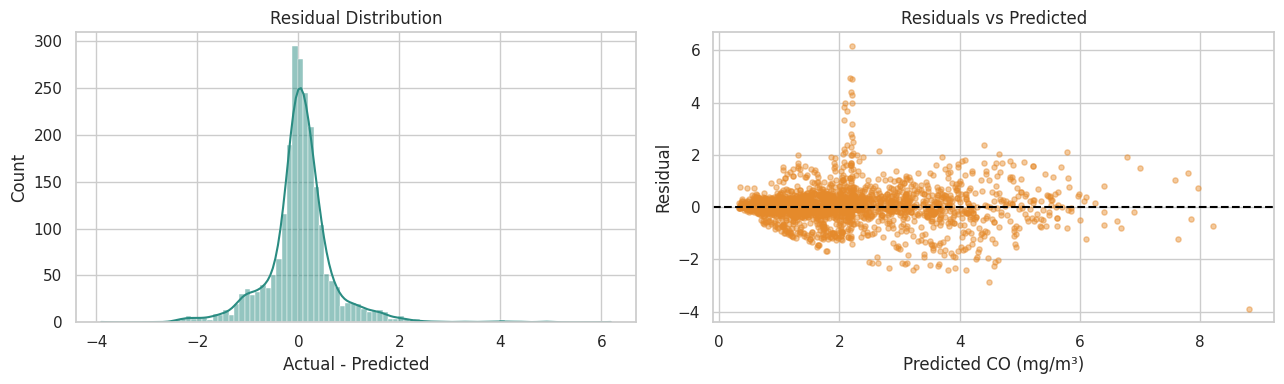

In [24]:
residuals = y_test.values - best_predictions
fig, axes = plt.subplots(1,2,figsize=(13,4))
sns.histplot(residuals, kde=True, ax=axes[0], color="#2A8C82")
axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Actual - Predicted")
axes[1].scatter(best_predictions, residuals, alpha=0.45, s=14, color="#E58A2B")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted CO (mg/m³)")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.savefig(FIG_DIR/"residual_analysis.png", dpi=180)
plt.show()

## 22. Permutation Feature Importance

,Feature,Mean Importance,Std
1,PT08.S2(NMHC),0.741246,0.005781
0,PT08.S1(CO),0.087965,0.002940
12,DayOfYear,0.056010,0.002285
8,Hour_Sin,0.032582,0.001326
9,Hour_Cos,0.007300,0.002845
3,PT08.S4(NO2),0.005901,0.001115
5,T,0.004584,0.002506
4,PT08.S5(O3),0.001632,0.001022
11,Month,-0.000087,0.000018
10,DayOfWeek,-0.000125,0.000551


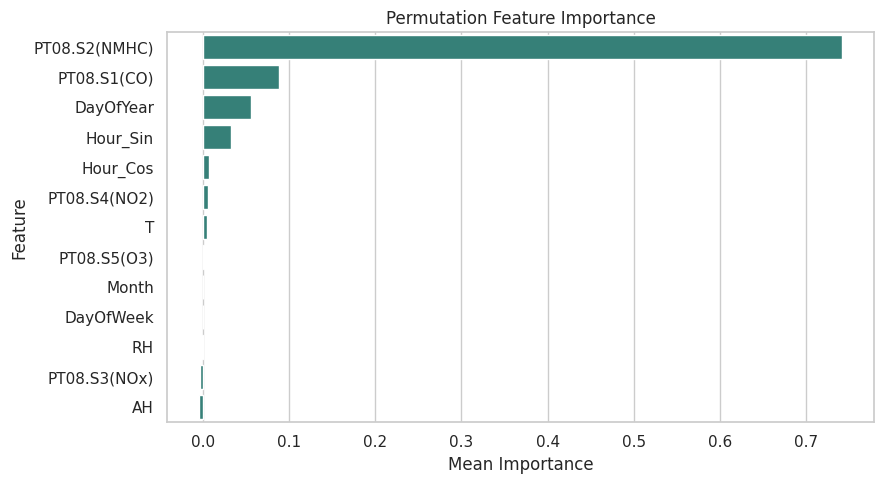

In [25]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
importance = pd.DataFrame({
    "Feature": feature_cols,
    "Mean Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Mean Importance", ascending=False)
display(importance)
importance.to_csv(OUTPUT_DIR/"feature_importance.csv", index=False)

plt.figure(figsize=(9,5))
sns.barplot(data=importance, x="Mean Importance", y="Feature", color="#2A8C82")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.savefig(FIG_DIR/"feature_importance.png", dpi=180)
plt.show()

## 23. Cross-Validation Comparison

In [26]:
cv_rows = []
for name, pipe in models.items():
    scores = cross_validate(
        pipe, X_train, y_train, cv=tscv,
        scoring={"rmse":"neg_root_mean_squared_error", "mae":"neg_mean_absolute_error", "r2":"r2"},
        n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Std CV RMSE": scores["test_rmse"].std(),
        "Mean CV MAE": -scores["test_mae"].mean(),
        "Mean CV R2": scores["test_r2"].mean()
    })
cv_results = pd.DataFrame(cv_rows).sort_values("Mean CV RMSE")
display(cv_results.round(4))
cv_results.to_csv(OUTPUT_DIR/"cross_validation_results.csv", index=False)

,Model,Mean CV RMSE,Std CV RMSE,Mean CV MAE,Mean CV R2
3,Random Forest,0.4978,0.2069,0.3382,0.8628
4,Gradient Boosting,0.4981,0.2412,0.3236,0.8651
0,Linear Regression,0.5787,0.2097,0.4261,0.8036
1,Decision Tree,0.5870,0.1851,0.4136,0.8066
2,KNN,0.6143,0.2412,0.4290,0.8005


## 24. Key Findings and Limitations

In [27]:
best_metrics = regression_metrics(y_test, best_predictions)
print("SELECTED MODEL:", best_model_name)
print("TEST MAE:", round(best_metrics["MAE"], 4), "mg/m³")
print("TEST RMSE:", round(best_metrics["RMSE"], 4), "mg/m³")
print("TEST R²:", round(best_metrics["R2"], 4))
print("\nTop predictors by permutation importance:")
display(importance.head(5))
print("\nLimitations:")
print("- CO(GT) is a pollutant concentration, not an official AQI value.")
print("- The data comes from one monitoring location and historical period.")
print("- Sensor drift and cross-sensitivity are documented dataset characteristics.")
print("- Model performance on this test period does not guarantee performance in another city or year.")

SELECTED MODEL: Gradient Boosting
TEST MAE: 0.4367 mg/m³
TEST RMSE: 0.6946 mg/m³
TEST R²: 0.7653

Top predictors by permutation importance:


,Feature,Mean Importance,Std
1,PT08.S2(NMHC),0.741246,0.005781
0,PT08.S1(CO),0.087965,0.002940
12,DayOfYear,0.056010,0.002285
8,Hour_Sin,0.032582,0.001326
9,Hour_Cos,0.007300,0.002845



Limitations:
- CO(GT) is a pollutant concentration, not an official AQI value.
- The data comes from one monitoring location and historical period.
- Sensor drift and cross-sensitivity are documented dataset characteristics.
- Model performance on this test period does not guarantee performance in another city or year.


## 25. Export Project Outputs
This cell creates a ZIP containing the generated charts and result tables. Download it and use the actual values in the report.

In [28]:
import shutil
results_zip = shutil.make_archive("/content/AQI_Project_Results", "zip", OUTPUT_DIR)
print("Created:", results_zip)
from google.colab import files
files.download(results_zip)

Created: /content/AQI_Project_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 26. Conclusion

This project demonstrates a supervised regression workflow for estimating hourly carbon monoxide concentration from air-quality sensor and meteorological measurements. The best model is selected using the lowest chronological test-set RMSE. The results should be interpreted as CO concentration prediction, not as an official AQI calculation.

**Before submission:** Run every cell from top to bottom, inspect the output tables and graphs, and use the actual printed metrics in the technical report. Do not report placeholder or assumed scores.